# ADP 22회 상황형 연습 - 풀이

**상황형 재구성 연습·예시 풀이이며 공식 원문/정답이 아닙니다.**

출처: DataManim ADP 22회 실기 문제 PDF

원 자료 조건: 첨부 자료의 문항·표·그림을 바탕으로 정리한 학습용 자료입니다.

문제는 동봉 상황형 문제지와 같습니다. 원문은 문항목록.json·추가_문항명세.json에 보존합니다. 순서대로 실행하며 각 대문항에서 고정한 자료·전처리·분할을 후속 문항에 재사용합니다. 통계 답안은 선정 근거 → 가정·가설 → 통계량·p-value → 기각 여부·상황 해석 순서로 작성합니다. 확률·구간 추정·관리도 문항에 불필요한 귀무가설을 만들지 않습니다.

실행: 해당 회차 폴더에서 위에서 아래로 실행합니다. 가설검정_답안.json은 실제 계산한 가설·수치·결론 기록입니다.

In [1]:
from pathlib import Path
import sys, platform, time, inspect, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display, Markdown
from scipy import stats
import statsmodels.api as sm
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, LinearRegression, RidgeCV
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVC, SVR
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, confusion_matrix,
    roc_auc_score, average_precision_score, mean_squared_error, mean_absolute_error, r2_score,
    silhouette_score)
from sklearn.inspection import permutation_importance
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.oneway import anova_oneway
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline as ImbPipeline

SEED = 42
HERE = Path.cwd()
DATA = HERE / 'data'
assert DATA.is_dir(), '압축을 전체 해제한 뒤, 노트북이 있는 회차 폴더를 작업 위치로 실행하세요.'
OUT = HERE / '실행결과'
OUT.mkdir(exist_ok=True)
font_path = HERE.parent / '공통' / 'NanumGothic-Regular.ttf'
if font_path.is_file():
    font_manager.fontManager.addfont(str(font_path))
    plt.rcParams['font.family'] = font_manager.FontProperties(fname=str(font_path)).get_name()
plt.rcParams.update({'axes.unicode_minus': False, 'figure.dpi': 110, 'font.size': 10})
pd.set_option('display.max_columns', 12)
pd.set_option('display.max_rows', 20)
print('Python', platform.python_version())
import sklearn, scipy, statsmodels, imblearn
print('numpy', np.__version__, 'pandas', pd.__version__, 'scikit-learn', sklearn.__version__,
      'scipy', scipy.__version__, 'statsmodels', statsmodels.__version__, 'imblearn', imblearn.__version__)

def load(name):
    return pd.read_csv(DATA / name if (DATA / name).exists() else DATA / (name + ".gz"))

def ohe():
    return OneHotEncoder(handle_unknown='ignore', **({'sparse_output': False} if 'sparse_output' in inspect.signature(OneHotEncoder).parameters else {'sparse': False}))

def reg_metrics(actual, predicted):
    a, b = np.asarray(actual, dtype=float), np.asarray(predicted, dtype=float)
    assert a.shape == b.shape and np.isfinite(a).all() and np.isfinite(b).all()
    mask = a != 0
    return {'MSE': mean_squared_error(a,b), 'RMSE': np.sqrt(mean_squared_error(a,b)),
            'MAE': mean_absolute_error(a,b), 'MAPE(%)': 100*np.mean(np.abs((a[mask]-b[mask])/a[mask])) if mask.any() else np.nan,
            'MAPE 제외 0개수': int((~mask).sum()), 'R2': r2_score(a,b)}

def class_metrics(actual, predicted, probability=None):
    a, b = np.asarray(actual), np.asarray(predicted)
    assert a.shape == b.shape
    result = {'Accuracy':accuracy_score(a,b), 'BalancedAccuracy':balanced_accuracy_score(a,b),
              'F1_macro':f1_score(a,b,average='macro',zero_division=0),
              'F1_weighted':f1_score(a,b,average='weighted',zero_division=0)}
    if probability is not None and set(np.unique(a)) == {0,1}:
        score = np.asarray(probability)
        score = score[:,1] if score.ndim == 2 else score
        result.update(ROC_AUC=roc_auc_score(a,score), AveragePrecision=average_precision_score(a,score))
    return result

def decision(p, alpha=.05):
    return '귀무가설 기각' if p < alpha else '귀무가설을 기각할 근거 부족'

def quality(frame):
    display(pd.DataFrame({'dtype':frame.dtypes.astype(str), 'missing':frame.isna().sum(), 'unique':frame.nunique()}))
    print('shape:', frame.shape, 'duplicate rows:', frame.duplicated().sum())
    display(frame.describe(include='all').T)

def plot_confusion(actual, prediction, labels=None, title='Confusion matrix'):
    order = np.unique(np.r_[actual,prediction]) if labels is None else labels
    matrix=confusion_matrix(actual,prediction,labels=order)
    fig,ax=plt.subplots(figsize=(5,4));im=ax.imshow(matrix,cmap='Blues')
    ax.set(xticks=range(len(order)),yticks=range(len(order)),xticklabels=order,yticklabels=order,
           xlabel='예측',ylabel='실제',title=title)
    for (i,j),value in np.ndenumerate(matrix):
        ax.text(j,i,int(value),ha='center',va='center',color='white' if value>matrix.max()/2 else 'black')
    fig.colorbar(im,ax=ax);fig.tight_layout();plt.show()
    return pd.DataFrame(matrix,index=order,columns=order)

def median_predict_time(model, X, repeat=5):
    model.predict(X)
    elapsed=[]
    for _ in range(repeat):
        start=time.perf_counter();model.predict(X);elapsed.append(time.perf_counter()-start)
    return float(np.median(elapsed))

class IQRClipper(TransformerMixin, BaseEstimator):
    def __init__(self, factor=1.5): self.factor=factor
    def fit(self, X, y=None):
        q1,q3=np.percentile(np.asarray(X,dtype=float),[25,75],axis=0)
        self.lower_=q1-self.factor*(q3-q1);self.upper_=q3+self.factor*(q3-q1)
        return self
    def transform(self, X): return np.clip(np.asarray(X,dtype=float),self.lower_,self.upper_)
# 상황형 답안 기록 초기화
_SCENARIO_ROOT=next(p for p in [Path.cwd()]+list(Path.cwd().parents) if (p/'기출문제/공통/scenario_inference.py').is_file())
sys.path.insert(0,str(_SCENARIO_ROOT/'기출문제/공통'))
from scenario_inference import (reset_reports, set_question, report_test, report_anova,
    report_correlations, report_adf, report_residuals, report_regression_diagnostics)
reset_reports(OUT)


Python 3.12.14
numpy 2.3.5 pandas 2.2.3 scikit-learn 1.8.0 scipy 1.17.0 statsmodels 0.14.6 imblearn 0.14.2


## 1. 당뇨 발병 자료 점검

의료기관은 Outcome을 예측하려 한다. Pregnancies·Glucose·BloodPressure·SkinThickness·Insulin·BMI·DiabetesPedigreeFunction·Age를 사용한다. 1~3번은 같은 환자 자료와 분할을 공유한다.

자료: data1.csv

### 1.1

발병 여부별 표본 수와 신체 특성의 분포·관계를 탐색하고 시각화하시오. 누락 또는 비현실적 측정값이 예측에 줄 영향을 설명하시오.

**판단 및 풀이 근거**

분포·타깃 비율·결측·중복을 확인합니다. Glucose·BloodPressure·SkinThickness·Insulin·BMI의 0은 생리적으로 부적절한 값일 수 있어 결측 후보로 처리합니다. Pregnancies=0은 유효하므로 유지합니다. Outcome의 클래스 비율과 결측 후보 비율을 시각화합니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

,dtype,missing,unique
Pregnancies,int64,0,17
Glucose,int64,0,136
BloodPressure,int64,0,47
SkinThickness,int64,0,51
Insulin,int64,0,186
BMI,float64,0,248
DiabetesPedigreeFunction,float64,0,517
Age,int64,0,52
Outcome,int64,0,2


shape: (768, 9) duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,81.976562,358.835058,0.000,62.00000,72.0000,80.00000,9999.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,44.934766,359.739733,0.000,27.30000,32.0000,36.60000,9999.00
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,34.447917,36.754727,21.000,24.00000,29.0000,41.00000,999.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


,결측 후보 0개수
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11


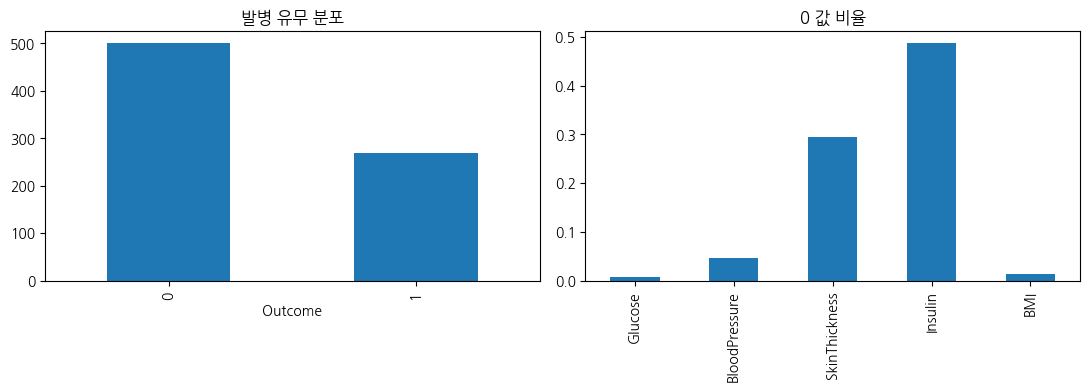

In [2]:
set_question('1.1')
diabetes=load('data1.csv');quality(diabetes)
invalid_zero=['Glucose','BloodPressure','SkinThickness','Insulin','BMI']
display(diabetes[invalid_zero].eq(0).sum().to_frame('결측 후보 0개수'))
fig,axs=plt.subplots(1,2,figsize=(11,4));diabetes.Outcome.value_counts().sort_index().plot.bar(ax=axs[0],title='발병 유무 분포')
diabetes[invalid_zero].eq(0).mean().plot.bar(ax=axs[1],title='0 값 비율');fig.tight_layout();plt.show()
X=diabetes.drop(columns='Outcome').replace({c:{0:np.nan} for c in invalid_zero});y=diabetes.Outcome.to_numpy();ids=np.arange(len(X))
train_valid,test_idx=train_test_split(ids,test_size=.2,stratify=y,random_state=SEED)
train_idx,valid_idx=train_test_split(train_valid,test_size=.25,stratify=y[train_valid],random_state=SEED)

### 1.2

측정 특성의 극단값을 조사하고 삭제·대체·보존 중 처리 방안을 선정하시오. 학습 자료에서 정한 기준을 검증 자료에 재사용하는 절차를 제시하시오.

**판단 및 풀이 근거**

단순히 극단값을 모두 제거하면 중요한 고위험 표본을 잃을 수 있습니다. 예제로 train 중앙값 대치 후 train IQR의 1.5배 경계에서 winsorization을 적용합니다. 같은 경계를 validation/test에 재사용합니다. 이는 자동으로 의학적 이상을 판정하는 규칙이 아니라 모델링 전처리 가정입니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

,train_median,IQR_lower,IQR_upper
Pregnancies,3.000,-6.500000,13.500000
Glucose,117.000,40.000000,200.000000
BloodPressure,72.000,40.000000,104.000000
SkinThickness,30.000,13.000000,45.000000
Insulin,125.000,105.500000,143.500000
BMI,32.400,13.800000,50.600000
DiabetesPedigreeFunction,0.389,-0.355375,1.245625
Age,29.000,0.000000,64.000000


Pregnancies                   1
Glucose                       0
BloodPressure                12
SkinThickness                37
Insulin                     200
BMI                           6
DiabetesPedigreeFunction     16
Age                          11
Name: 대체한 극단값 개수, dtype: int64

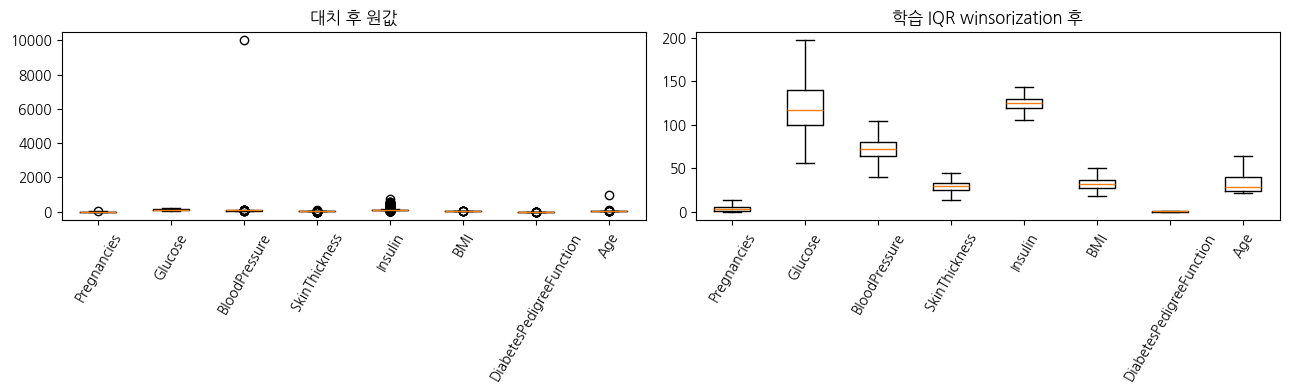

In [3]:
set_question('1.2')
preprocess=Pipeline([('impute',SimpleImputer(strategy='median')),('clip',IQRClipper()),('scale',StandardScaler())])
train_processed=preprocess.fit_transform(X.iloc[train_idx])
median=preprocess.named_steps['impute'];clip=preprocess.named_steps['clip']
display(pd.DataFrame({'train_median':median.statistics_,'IQR_lower':clip.lower_,'IQR_upper':clip.upper_},index=X.columns))
before=median.transform(X.iloc[train_idx]);after=clip.transform(before)
display(pd.Series((before!=after).sum(axis=0),index=X.columns,name='대체한 극단값 개수'))
fig,axs=plt.subplots(1,2,figsize=(13,4));axs[0].boxplot(before);axs[1].boxplot(after)
for ax,title in zip(axs,['대치 후 원값','학습 IQR winsorization 후']):ax.set(xticks=range(1,len(X.columns)+1),xticklabels=X.columns,title=title);ax.tick_params(axis='x',rotation=60)
fig.tight_layout();plt.show()

### 1.3

앞의 탐색·품질 점검 결과를 종합하여 후속 모델링에서 통제할 누출·불균형·오류 비용과 평가 지표를 설명하시오.

**판단 및 풀이 근거**

0 값의 의미를 변수별로 구분하고 생리적으로 가능한 극단값을 무조건 오류로 단정하지 않습니다. Outcome를 대치·스케일링·PCA 입력에 포함하지 않습니다. 전체 데이터에서 먼저 리샘플링하면 평가 누수가 생기므로 train 또는 CV 학습 폴드 안에서만 수행합니다. 이 자료의 성능을 다른 집단·실제 의료 환경으로 일반화하려면 별도 외부 검증이 필요합니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

In [4]:
set_question('1.3')
assert set(train_idx).isdisjoint(test_idx) and set(valid_idx).isdisjoint(test_idx)
assert train_processed.shape[1]==8
print('분할 크기:',len(train_idx),len(valid_idx),len(test_idx))
print('train 타깃 비율:',pd.Series(y[train_idx]).value_counts(normalize=True).sort_index().to_dict())
print('평가자료는 원 비율 유지:',pd.Series(y[test_idx]).value_counts(normalize=True).sort_index().to_dict())

분할 크기: 460 154 154
train 타깃 비율: {0: 0.6521739130434783, 1: 0.34782608695652173}
평가자료는 원 비율 유지: {0: 0.6493506493506493, 1: 0.35064935064935066}


## 2. 발병 표본 불균형 대응

1번에서 고정한 학습 자료만 사용해 표본 불균형 대안을 비교한다. 검증·시험 자료의 원래 발병 비율은 유지한다.

자료: data1.csv

### 2.1

소수 발병 표본의 영향력을 높이기 위한 표본 증가 방안을 선택하시오. 선택 근거·절차·처리 전후 표본 수와 위험을 제시하시오.

**판단 및 풀이 근거**

SMOTE는 소수 클래스 이웃 사이에서 새 표본을 생성하여 train의 두 클래스를 같은 수로 맞춥니다. 단순 복제보다 다양한 위치를 만들지만 잘못된 경계·잡음도 확장할 수 있습니다. 학습 특성의 대치·표준화 후 적용하며 validation/test에는 합성 표본을 추가하지 않습니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

In [5]:
set_question('2.1')
over=SMOTE(random_state=SEED,k_neighbors=5)
X_over,y_over=over.fit_resample(train_processed,y[train_idx])
display(pd.DataFrame({'original':pd.Series(y[train_idx]).value_counts(),'SMOTE':pd.Series(y_over).value_counts()}).fillna(0).astype(int))
print('SMOTE 특성 shape:',X_over.shape);assert pd.Series(y_over).value_counts().nunique()==1

,original,SMOTE
0,300,300
1,160,300


SMOTE 특성 shape: (600, 8)


### 2.2

다수 표본을 줄이는 대안을 적용하시오. 앞선 방법과 정보 손실·연산 비용·일반화 측면의 장단점을 설명하시오.

**판단 및 풀이 근거**

RandomUnderSampler는 다수 클래스의 일부를 무작위로 선택하여 두 클래스 수를 맞춥니다. 학습량과 비용이 줄지만 유용한 다수 표본을 버릴 수 있습니다. 원자료의 train만 줄이고 validation/test는 보존합니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

In [6]:
set_question('2.2')
under=RandomUnderSampler(random_state=SEED)
X_under,y_under=under.fit_resample(train_processed,y[train_idx])
display(pd.DataFrame({'original':pd.Series(y[train_idx]).value_counts(),'under':pd.Series(y_under).value_counts()}).fillna(0).astype(int))
print('언더샘플링 특성 shape:',X_under.shape);assert pd.Series(y_under).value_counts().nunique()==1

,original,under
0,300,160
1,160,160


언더샘플링 특성 shape: (320, 8)


### 2.3

두 대안 중 하나를 후속 비교에 사용하도록 결정하시오. 결정 기준을 명시하고 검증 자료를 재표본화하면 안 되는 이유를 설명하시오.

**판단 및 풀이 근거**

동일한 로지스틱 회귀와 validation에서 두 방법을 비교하고 macro F1이 높은 방법을 택합니다. accuracy·balanced accuracy·ROC-AUC도 함께 확인합니다. 선택 이유는 관측된 validation 성능과 표본 보존·학습 시간의 trade-off로 설명하며, 불균형 비율만으로 SMOTE가 항상 우수하다고 단정하지 않습니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

In [7]:
set_question('2.3')
valid_processed=preprocess.transform(X.iloc[valid_idx]);sampling_rows=[]
for name,tx,ty in [('over',X_over,y_over),('under',X_under,y_under)]:
    model=LogisticRegression(max_iter=2000,random_state=SEED);start=time.perf_counter();model.fit(tx,ty)
    sampling_rows.append({'sampling':name,**class_metrics(y[valid_idx],model.predict(valid_processed),model.predict_proba(valid_processed)),
                          'fit_seconds':time.perf_counter()-start,'train_rows':len(ty)})
sampling_results=pd.DataFrame(sampling_rows).set_index('sampling');display(sampling_results)
sampling_choice=sampling_results.F1_macro.idxmax();print('validation macro F1 기준 선택:',sampling_choice)
print('SMOTE는 원래 다수 표본을 유지하고, under는 자료와 학습 시간을 줄이는 대신 일부 정보를 포기합니다.')
def sampler():return SMOTE(random_state=SEED) if sampling_choice=='over' else RandomUnderSampler(random_state=SEED)

,Accuracy,BalancedAccuracy,F1_macro,F1_weighted,ROC_AUC,AveragePrecision,fit_seconds,train_rows
sampling,,,,,,,,
over,0.75974,0.738333,0.737310,0.760239,0.855185,0.740943,0.023046,600
under,0.75974,0.755370,0.745022,0.763320,0.858704,0.746721,0.020174,320


validation macro F1 기준 선택: under
SMOTE는 원래 다수 표본을 유지하고, under는 자료와 학습 시간을 줄이는 대신 일부 정보를 포기합니다.


## 3. 발병 예측 모형 비교

1·2번의 환자 자료와 학습 전처리·평가 구간을 이어 사용한다. 정확도와 속도는 실제 측정값으로 비교한다.

자료: data1.csv

### 3.1

예측 원리가 다른 모형을 최소 3개 제안하시오. 속도 우선 후보와 정확도 우선 후보를 포함해 최소 2개를 적합하고 선정 근거를 설명하시오.

**판단 및 풀이 근거**

후보로 로지스틱 회귀·Random Forest·RBF SVM을 제시하고 세 모델을 모두 구현합니다. 속도 후보는 저차원 선형 로지스틱 회귀, 정확도 후보는 비선형·상호작용을 포착하는 Random Forest입니다. 어느 모형이 실제로 빠르고 정확한지는 아래 측정값으로 확인합니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

In [8]:
set_question('3.1')
classifiers={'Logistic':LogisticRegression(max_iter=2000,random_state=SEED),
             'RandomForest':RandomForestClassifier(n_estimators=160,min_samples_leaf=2,random_state=SEED,n_jobs=1),
             'SVM':SVC(C=3,kernel='rbf',probability=True,random_state=SEED)}
models={};rows=[]
for name,est in classifiers.items():
    model=ImbPipeline([('impute',SimpleImputer(strategy='median')),('clip',IQRClipper()),('scale',StandardScaler()),('sampler',sampler()),('model',est)])
    start=time.perf_counter();model.fit(X.iloc[train_idx],y[train_idx]);fit_time=time.perf_counter()-start
    rows.append({'model':name,**class_metrics(y[valid_idx],model.predict(X.iloc[valid_idx]),model.predict_proba(X.iloc[valid_idx])),
                 'fit_seconds':fit_time,'predict_seconds':median_predict_time(model,X.iloc[valid_idx])});models[name]=model
comparison=pd.DataFrame(rows).set_index('model');display(comparison)

,Accuracy,BalancedAccuracy,F1_macro,F1_weighted,ROC_AUC,AveragePrecision,fit_seconds,predict_seconds
model,,,,,,,,
Logistic,0.759740,0.755370,0.745022,0.763320,0.858704,0.746721,0.014725,0.002453
RandomForest,0.759740,0.768148,0.749593,0.764650,0.866667,0.748500,0.540723,0.037308
SVM,0.772727,0.778148,0.761789,0.777036,0.846111,0.699688,0.068642,0.009475


### 3.2

같은 검증 자료에서 성능·학습 시간·예측 시간을 비교하고 최종 모형을 정하시오. 선택에 쓰지 않은 시험 자료의 결과와 한계를 보고하시오.

**판단 및 풀이 근거**

accuracy뿐 아니라 클래스별 오류와 macro F1을 함께 봅니다. validation accuracy 기준 최종 모델과 예측 시간 기준 가장 빠른 모델을 보고하고, 선택된 정확도 모델만 test에서 평가합니다. 테스트 성능으로 다시 모델을 고르지 않습니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

validation accuracy 선택: SVM 예측 속도 측정 선택: Logistic


Accuracy            0.727273
BalancedAccuracy    0.721852
F1_macro            0.711508
F1_weighted         0.731652
ROC_AUC             0.811667
AveragePrecision    0.637086
Name: 최종 test, dtype: float64

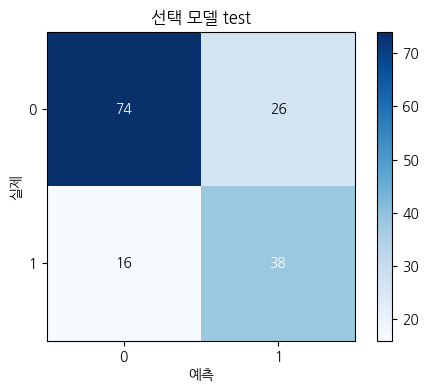

,0,1
0,74,26
1,16,38


In [9]:
set_question('3.2')
best_name=comparison.Accuracy.idxmax();fast_name=comparison.predict_seconds.idxmin();best=models[best_name]
print('validation accuracy 선택:',best_name,'예측 속도 측정 선택:',fast_name)
test_prediction=best.predict(X.iloc[test_idx]);test_prob=best.predict_proba(X.iloc[test_idx])
display(pd.Series(class_metrics(y[test_idx],test_prediction,test_prob),name='최종 test'))
display(plot_confusion(y[test_idx],test_prediction,labels=[0,1],title='선택 모델 test'))
comparison.to_csv(OUT/'당뇨_모델_validation비교.csv')

### 3.3

특성 수를 줄여 예측을 빠르게 할 수 있는지 확인하시오. 학습 자료로만 차원 축소를 적합하고, 축소 전후 같은 모형의 성능·시간을 비교해 도입 여부를 판단하시오.

**판단 및 풀이 근거**

표준화 후 PCA로 train 분산의 95%를 보존하고 같은 종류의 선택 모델을 재학습합니다. PCA는 train 안에서만 적합하고 샘플링 전에 적용합니다. 입력이 8개뿐이라 PCA 변환 비용 때문에 전체 예측 시간이 오히려 늘 수도 있습니다. 성능·성분 수·변환을 포함한 시간을 측정하여 개선 여부를 판단합니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

In [10]:
set_question('3.3')
pca_model=ImbPipeline([('impute',SimpleImputer(strategy='median')),('clip',IQRClipper()),('scale',StandardScaler()),
                       ('pca',PCA(n_components=.95,svd_solver='full')),('sampler',sampler()),('model',clone(classifiers[best_name]))])
start=time.perf_counter();pca_model.fit(X.iloc[train_idx],y[train_idx]);pca_fit=time.perf_counter()-start
rows=[{'version':'original',**class_metrics(y[valid_idx],best.predict(X.iloc[valid_idx]),best.predict_proba(X.iloc[valid_idx])),
       'components':X.shape[1],'fit_seconds':comparison.loc[best_name,'fit_seconds'],'predict_seconds':median_predict_time(best,X.iloc[valid_idx])},
      {'version':'PCA',**class_metrics(y[valid_idx],pca_model.predict(X.iloc[valid_idx]),pca_model.predict_proba(X.iloc[valid_idx])),
       'components':pca_model.named_steps['pca'].n_components_,'fit_seconds':pca_fit,'predict_seconds':median_predict_time(pca_model,X.iloc[valid_idx])}]
dim_comparison=pd.DataFrame(rows).set_index('version');display(dim_comparison)
print('PCA 보존 분산:',pca_model.named_steps['pca'].explained_variance_ratio_.sum())
display(pd.Series(class_metrics(y[test_idx],pca_model.predict(X.iloc[test_idx]),pca_model.predict_proba(X.iloc[test_idx])),name='PCA 버전 test 보고용'))
print('PCA 포함 예측 시간 비:',dim_comparison.loc['PCA','predict_seconds']/dim_comparison.loc['original','predict_seconds'])

,Accuracy,BalancedAccuracy,F1_macro,F1_weighted,ROC_AUC,AveragePrecision,components,fit_seconds,predict_seconds
version,,,,,,,,,
original,0.772727,0.778148,0.761789,0.777036,0.846111,0.699688,8,0.068642,0.002621
PCA,0.759740,0.763889,0.748177,0.764296,0.848981,0.726696,7,0.030951,0.003608


PCA 보존 분산: 0.9559429646532448


Accuracy            0.727273
BalancedAccuracy    0.721852
F1_macro            0.711508
F1_weighted         0.731652
ROC_AUC             0.802963
AveragePrecision    0.634054
Name: PCA 버전 test 보고용, dtype: float64

PCA 포함 예측 시간 비: 1.3764126777577068


## 4. 금속 성분 산포

품질팀은 독립 추출한 제품의 금속 성분 함유량으로 공정의 산포가 기준과 달라졌는지 조사한다. 단일 공정의 정규 모집단을 가정하고 기준 분산은 1.3이다. 기본 질문은 양측 차이, 유의수준은 5%다. 제조사별 구분은 제공되지 않는다.

자료: content.csv

### 4.1

자료 구조와 조사 목적에 적절한 검정 방법을 선택하고 선정 근거·가정을 설명하시오. 기준 분산에 대한 귀무가설과 대립가설을 작성하시오.

**판단 및 풀이 근거**

단일 content 열만 있으므로 제조사 간 분산 비교는 할 수 없습니다. 원문이 요구한 양측 단일 분산 검정으로 H0: σ²=1.3, H1: σ²≠1.3을 설정합니다. “1.3 초과이면 불량”이라는 품질 질문은 방향성 있는 σ²>1.3 검정에 해당하므로 이를 보조로 구분하여 보고합니다. 표본의 독립성과 정규성 가정이 필요합니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

In [11]:
set_question('4.1')
content=load('content.csv')['content'].dropna().to_numpy()
print('H0: variance=1.3; H1(two-sided): variance != 1.3; alpha=.05')
print('표본 n:',len(content),'정규성 Shapiro p:',stats.shapiro(content).pvalue)

H0: variance=1.3; H1(two-sided): variance != 1.3; alpha=.05
표본 n: 200 정규성 Shapiro p: 0.4605726542566234


### 4.2

선택한 검정의 통계량·자유도·양측 p-value를 계산하고 분산의 95% 신뢰구간을 제시하시오.

**판단 및 풀이 근거**

정규 모집단에서 (n−1)s²/1.3은 자유도 n−1의 카이제곱 분포를 따릅니다. 양측 p값은 두 꼬리 확률의 두 배(최대 1)로 계산합니다. 모분산 95% 신뢰구간을 함께 제시합니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

In [12]:
set_question('4.2')
n=len(content);sample_variance=np.var(content,ddof=1);df=n-1;statistic=(n-1)*sample_variance/1.3
left=stats.chi2.cdf(statistic,df);right=stats.chi2.sf(statistic,df)
p_two=min(1.,2*min(left,right));variance_ci=((n-1)*sample_variance/stats.chi2.ppf(.975,df),(n-1)*sample_variance/stats.chi2.ppf(.025,df))
display(pd.Series({'n':n,'sample_variance':sample_variance,'chi2':statistic,'df':df,'two_sided_p':p_two,'right_sided_p':right,'variance_CI_low':variance_ci[0],'variance_CI_high':variance_ci[1]}))

n                   2.000000e+02
sample_variance     2.144623e+00
chi2                3.282923e+02
df                  1.990000e+02
two_sided_p         4.272667e-08
right_sided_p       2.136333e-08
variance_CI_low     1.778549e+00
variance_CI_high    2.637274e+00
dtype: float64

### 4.3

p-value와 유의수준으로 귀무가설 기각 여부를 판단하고 품질관리 맥락의 결론을 작성하시오. 분산이 기준을 초과하는지만 묻는 경우의 가설·p-value와 구분하시오.

**판단 및 풀이 근거**

정규 모집단 한 표본의 분산은 카이제곱 분포로 추론한다. 기본 양측 H0: σ²=1.3, H1: σ²≠1.3과 불량 초과 방향 H0: σ²≤1.3, H1: σ²>1.3을 구분한다.

**계산·해석 상세**

양측 p값과 0.05를 비교하여 H0의 기각 여부를 결정합니다. p≥0.05는 분산이 1.3임을 증명하는 의미가 아닙니다. 표본 분산의 방향과 상측 p값을 함께 제시해 품질 한계 초과 주장과 양측 차이 검정을 혼동하지 않습니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 가설·통계량·p-value·기각 여부·상황 결론을 함께 출력하며 수치는 실행 결과에 따라 결정합니다.

In [13]:
set_question('4.3')
print('양측 검정:',decision(p_two));print('분산 1.3 초과에 대한 상측 검정:',decision(right))
print('표본 분산:',sample_variance,'모분산 95% 구간:',variance_ci)

# 상황형 요구: 가설·실제 수치·기각 여부·맥락 결론
report_test('정규 한 표본 분산 양측 검정','sigma^2=1.3','sigma^2 != 1.3',statistic,p_two,'이 공정의 성분 분산이 기준 1.3과 다르다','단일 정규 모집단·독립 표본. 제조사 간 비교 자료는 아님.',df=df)
report_test('보조: 분산 상측 검정','sigma^2 <= 1.3','sigma^2 > 1.3',statistic,right,'이 공정의 성분 분산이 1.3을 초과한다','양측 결론과 목적이 다름. 방향은 결과 관측 전에 정해야 한다.',df=df)

양측 검정: 귀무가설 기각
분산 1.3 초과에 대한 상측 검정: 귀무가설 기각
표본 분산: 2.1446230524620504 모분산 95% 구간: (np.float64(1.778548730309166), np.float64(2.6372740252982885))
{
  "question": "4.3",
  "method": "정규 한 표본 분산 양측 검정",
  "H0": "sigma^2=1.3",
  "H1": "sigma^2 != 1.3",
  "statistic": 328.2922980307293,
  "p_value": 4.2726668550172056e-08,
  "alpha": 0.05,
  "reject_H0": true,
  "assumptions": "단일 정규 모집단·독립 표본. 제조사 간 비교 자료는 아님.",
  "conclusion": "귀무가설을 기각한다. 이 공정의 성분 분산이 기준 1.3과 다르다는 통계적 근거가 있다.",
  "df": 199
}
{
  "question": "4.3",
  "method": "보조: 분산 상측 검정",
  "H0": "sigma^2 <= 1.3",
  "H1": "sigma^2 > 1.3",
  "statistic": 328.2922980307293,
  "p_value": 2.1363334275086028e-08,
  "alpha": 0.05,
  "reject_H0": true,
  "assumptions": "양측 결론과 목적이 다름. 방향은 결과 관측 전에 정해야 한다.",
  "conclusion": "귀무가설을 기각한다. 이 공정의 성분 분산이 1.3을 초과한다는 통계적 근거가 있다.",
  "df": 199
}


## 5. Lot별 품질 감시

각 Lot에서 200개를 검사한 불량 개수 자료가 제공된다. 공정 변화 감시에 앞서 개수가 정수인지 확인해야 한다. 원 배포 자료에 소수 개수가 포함되어 있어 정식 품질 판정 가능 여부를 검토한다.

자료: error.csv

### 5.1

불량 비율의 변화를 감시할 도구를 선정하고 중심선·상한·하한을 계산하시오. 입력값의 개수 조건을 검증하고 계산의 적용 가능성을 설명하시오.

**판단 및 풀이 근거**

n=200이 일정하므로 p관리도의 CL=전체 불량수/전체 검사수, UCL=CL+3√(CL(1−CL)/200), LCL=max(0,CL−3√(CL(1−CL)/200))를 계산합니다. 원자료에 4.5 같은 소수 불량수가 있어 실제 이항 개수 자료로는 유효하지 않습니다. 이를 임의로 반올림·두 배 하지 않고, 아래는 원문 수치에 대한 형식적 산출물로 표시하며 정식 관리도 판정은 진짜 개수 자료 확인 전까지 유보합니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

In [14]:
set_question('5.1')
errors=load('error.csv');counts=errors.error_case_number.to_numpy(dtype=float);sample_n=200
valid_counts=np.all((counts>=0)&(counts<=sample_n)&(counts==np.floor(counts)))
CL=counts.sum()/(len(counts)*sample_n);sigma=np.sqrt(CL*(1-CL)/sample_n)
UCL=min(1.,CL+3*sigma);LCL=max(0.,CL-3*sigma)
print('정수 개수 검증:',valid_counts,'비정수 lot 개수:',np.sum(counts!=np.floor(counts)))
display(pd.Series({'CL':CL,'UCL':UCL,'LCL':LCL,'n_per_lot':sample_n,'lot_count':len(counts)}))
assert not valid_counts, '이 배포본에는 소수 개수 문제가 있다는 점을 재확인하세요.'

정수 개수 검증: False 비정수 lot 개수: 46


CL             0.017050
UCL            0.044512
LCL            0.000000
n_per_lot    200.000000
lot_count    100.000000
dtype: float64

### 5.2

Lot 순서에 따른 불량 비율과 한계를 시각화하시오. 형식적 한계 초과와 실제 공정 이상 판정을 구분하고, 자료 정정 전 가능한 결론의 범위를 설명하시오.

**판단 및 풀이 근거**

원자료를 p=불량값/200으로 표시하고 같은 CL/UCL/LCL을 겹칩니다. 관리한계를 벗어난 점은 형식적으로 표시하지만, 소수 개수 문제 때문에 실제 공정의 이상 판정을 주장하지 않습니다. 원자료가 다른 비율·환산량이었다면 단위와 분모를 확인한 뒤 적절한 관리도로 다시 분석해야 합니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

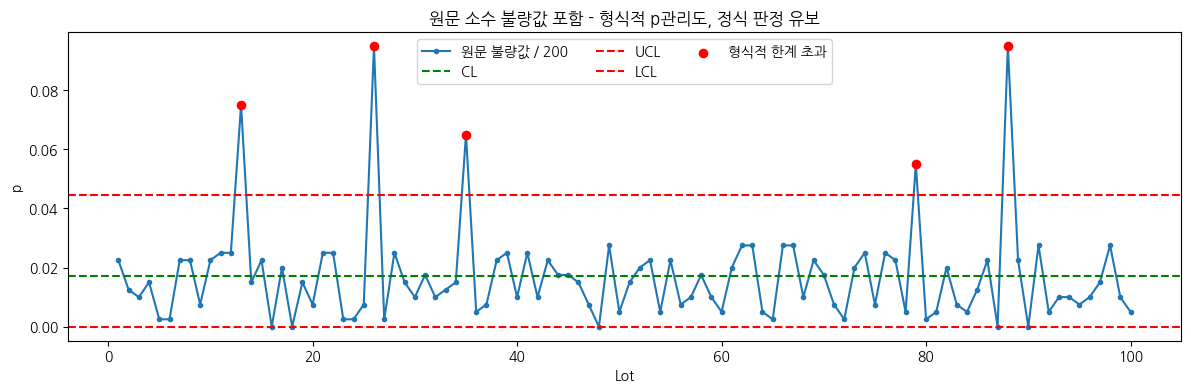

,iot_number,error_case_number,p,formal_outside
0,1,4.5,0.0225,False
1,2,2.5,0.0125,False
2,3,2.0,0.0100,False
3,4,3.0,0.0150,False
4,5,0.5,0.0025,False


형식적 한계 초과 수: 5 (실제 공정 이상 판정으로 사용하지 않음)


In [15]:
set_question('5.2')
proportions=counts/sample_n;outside=(proportions>UCL)|(proportions<LCL)
fig,ax=plt.subplots(figsize=(12,4));ax.plot(errors.iot_number,proportions,marker='o',ms=3,label='원문 불량값 / 200')
for value,name,color in [(CL,'CL','green'),(UCL,'UCL','red'),(LCL,'LCL','red')]:ax.axhline(value,color=color,ls='--',label=name)
ax.scatter(errors.iot_number[outside],proportions[outside],color='red',s=35,zorder=3,label='형식적 한계 초과')
ax.set(title='원문 소수 불량값 포함 - 형식적 p관리도, 정식 판정 유보',xlabel='Lot',ylabel='p');ax.legend(ncol=3);fig.tight_layout();plt.show()
display(errors.assign(p=proportions,formal_outside=outside).head())
print('형식적 한계 초과 수:',int(outside.sum()),'(실제 공정 이상 판정으로 사용하지 않음)')

## 제출 전 확인

- 문항별 요구 산출물과 수치를 위 결과에서 확인합니다.
- 데이터 변형·모형·지표·가설의 조건을 답안과 함께 제출합니다.
- p ≥ 0.05는 귀무가설이 참임을 입증하는 것이 아니라 기각 근거 부족입니다.
- 모델 선택은 validation 결과로 했으며 최종 test 지표로 재튜닝하지 않습니다.
- 원문 표현의 모호성·자료의 오류는 풀이에서 명시하고 임의로 원문을 수정하지 않았습니다.